In [2]:
import selfies as sf
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole  # 用于在 Jupyter 中显示图像

In [18]:
# rxn_smi = "[OH:1][c:2]1[cH:3][cH:4][c:5]([CH2:9][CH2:10][NH3+:11])[cH:6][c:7]1[OH:8]>>[O:1]=[C:2]1[CH:3]=[CH:4][C:5]([CH2:9][CH2:10][NH2:11])=[CH:6][C:7]1=[O:8]"
rxn_smi = "[OH:1][CH2:2][c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][c:10]1[O:11][CH3:12]>>[O:1]=[CH:2][c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][c:10]1[O:11][CH3:12]"
rsmi, psmi = rxn_smi.split('>>')
rsmi, psmi

('[OH:1][CH2:2][c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][c:10]1[O:11][CH3:12]',
 '[O:1]=[CH:2][c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][c:10]1[O:11][CH3:12]')

In [19]:
sf.encoder(rsmi)

'[OH1][CH2][CH0][=CH1][CH1][=CH0][Branch1][Ring1][OH0][CH3][CH1][=CH0][Ring1][Branch2][OH0][CH3]'

In [20]:
sf.decoder(sf.encoder(rsmi))

'[OH1][CH2][CH0]1=[CH1][CH1]=[CH0]([OH0][CH3])[CH1]=[CH0]1[OH0][CH3]'

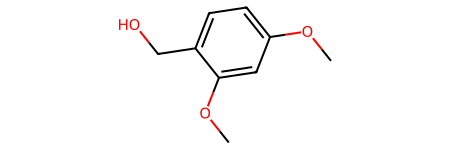

In [22]:
Chem.MolFromSmiles(sf.decoder(sf.encoder(rsmi)))

In [23]:
sf.encoder(psmi)

'[OH0][=CH1][CH0][=CH1][CH1][=CH0][Branch1][Ring1][OH0][CH3][CH1][=CH0][Ring1][Branch2][OH0][CH3]'

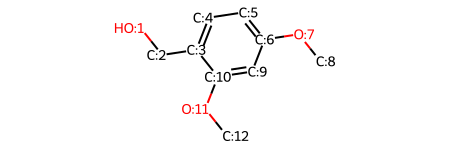

In [24]:
Chem.MolFromSmiles(rsmi)

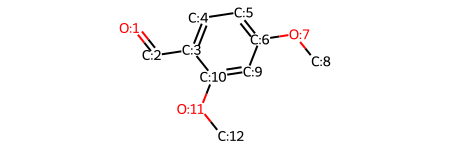

In [25]:
Chem.MolFromSmiles(psmi)

In [ ]:
import selfies as sf
from group_selfies.group_mol_graph import Group
from group_selfies.group_grammar import GroupGrammar
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.drawMolsSameScale = False # DrawMolsZoomed
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

import matplotlib.pyplot as plt
import numpy as np
from group_selfies.utils.fragment_utils import fragment_mols
from tqdm import tqdm
from pathos.multiprocessing import ProcessingPool as Pool
import re
import random

In [30]:
def grid(mols, molsPerRow=10):
    return Draw.MolsToGridImage(mols, molsPerRow=molsPerRow, maxMols=1000, subImgSize=(125, 125), useSVG=True)

def split_selfies(selfies: str):

    left_idx = selfies.find("[")

    while 0 <= left_idx < len(selfies):
        right_idx = selfies.find("]", left_idx + 1)
        if right_idx == -1:
            raise ValueError("malformed SELFIES string, hanging '[' bracket")

        next_symbol = selfies[left_idx: right_idx + 1]
        yield next_symbol

        left_idx = right_idx + 1
        if selfies[left_idx: left_idx + 1] == ".":
            yield "."
            left_idx += 1

def shuffle(selfies):
    """
    Shuffle a SELFIES string.
    """
    return "".join(sorted(split_selfies(selfies), key=lambda x: random.random()))

Fragment vocabulary size: 23


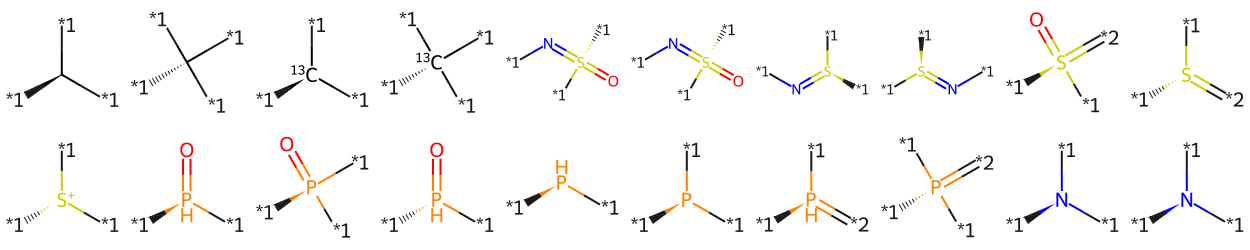

In [32]:
smis = [
    '[cH:1]1[cH:2][c:10]2[c:13]([cH:3][c:9]1[O:30][C@H:22]1[C@H:20]([OH:26])[C@@H:19]([OH:25])[C@H:18]([OH:24])[C@@H:17]([CH2:6][OH:23])[O:32]1)[O:27][CH2:7][C@H:12]1[c:11]3[cH:4][c:15]4[c:16]([cH:5][c:14]3[O:31][C@@H:21]21)[O:29][CH2:8][O:28]4',
    '[cH:1]1[cH:2][c:10]2[c:13]([cH:3][c:9]1[O:30][C@H:22]1[C@H:20]([OH:26])[C@@H:19]([OH:25])[C@H:18]([OH:24])[C@@H:17]([CH2:6][O:23][C:47]([CH2:39][C:46](=[O:65])[OH:66])=[O:67])[O:32]1)[O:27][CH2:7][C@H:12]1[c:11]3[cH:4][c:15]4[c:16]([cH:5][c:14]3[O:31][C@@H:21]21)[O:29][CH2:8][O:28]4',
    '[cH:1]1[cH:2][c:10]2[c:13]([cH:3][c:9]1[OH:30])[O:27][CH2:7][C@H:12]1[c:11]3[cH:4][c:15]4[c:16]([cH:5][c:14]3[O:31][C@@H:21]21)[O:29][CH2:8][O:28]4',
    '[cH:1]1[cH:2][c:10]2[c:13]([cH:3][c:9]1[O:30][C@H:22]1[C@H:20]([OH:26])[C@@H:19]([OH:25])[C@H:18]([OH:24])[C@@H:17]([CH2:6][OH:23])[O:32]1)[O:27][CH2:7][C@H:12]1[c:11]3[cH:4][c:15]4[c:16]([cH:5][c:14]3[O:31][C@@H:21]21)[O:29][CH2:8][O:28]4',
]
selfis = [sf.encoder(smi) for smi in smis]
empty_grammar = GroupGrammar()

N = 100_000

load_from_disk = True

if load_from_disk:
	grammar = GroupGrammar.essential_set()
    # grammar = GroupGrammar.from_file('useful30.txt') | GroupGrammar.essential_set() #load
else:
    # extracting a set of reasonable groups using fragmentation
    fragments = fragment_mols(smis, convert=True, method='default', target=500) # use custom fragmentation technique
    vocab_fragment = dict([(f'frag{idx}', Group(f'frag{idx}', frag)) for idx, frag in enumerate(fragments)])
    grammar = GroupGrammar(vocab_fragment)
    grammar.to_file('zinc_test_grammar.txt')
    
print('Fragment vocabulary size:', len(grammar.vocab))
display(grid([g.mol for g in grammar.vocab.values()][:20]))


In [10]:
from rdkit import Chem
from rdkit.Chem import AllChem
from group_selfies import (
    fragment_mols, 
    Group, 
    MolecularGraph, 
    GroupGrammar, 
    group_encoder
)

from rdkit.Chem.Draw import IPythonConsole

from IPython.display import display
from rdkit import RDLogger


RDLogger.DisableLog('rdApp.*') 



In [11]:
# selfies = "[O][C][=Branch1][C][=O][=C]"
selfies = "[C][C][C][C][C][Ring1][Ring2][Ring1][Ring2]"
decoded_smi = sf.decoder(selfies)
print(decoded_smi)


CC=1CCC=1


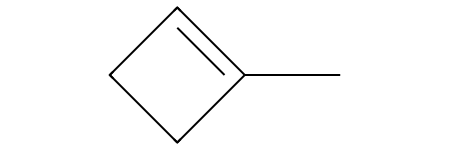

In [12]:
Chem.MolFromSmiles(decoded_smi)

In [28]:
from tdc import Oracle

# 计算合成可及性分数
sa_oracle = Oracle('SA')
sa_score = sa_oracle('CCOc1cc(C=Nn2c(S(N)(=O)=O)cc(c2C)C)ccc1O') # -> 3.3...
print(sa_score)

# 计算类药性 (Quantitative Estimate of Drug-likeness)
qed_oracle = Oracle('QED')
qed_score = qed_oracle('CCOc1cc(C=Nn2c(S(N)(=O)=O)cc(c2C)C)ccc1O') # -> 0.7...
print(qed_score)

# 计算脂水分配系数 (越高越亲脂)
logp_oracle = Oracle('LogP')
logp_score = logp_oracle('CCOc1cc(C=Nn2c(S(N)(=O)=O)cc(c2C)C)ccc1O') # -> 3.2...
print(logp_score)

Found local copy...
Found local copy...


0.0
0.810276702390984
0.0
